# EMQA_L1_negative_prices

**Negative day-ahead prices per year and by hour of the day**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_negative_prices/EMQA_L1_negative_prices.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Hours with negative day-ahead prices per year in Romania, Bulgaria, Hungary and Germany-Luxembourg (hour-equivalents: a 15-minute market time unit counts 0.25 h), and the Romanian negative hours by hour of the day since 2024.

**Data:** 2018 to 2026-10-31; a 15-min MTU counts 0.25 h. **Source:** energy-charts.info (Fraunhofer ISE); prices from the exchanges OPCOM (RO), IBEX (BG), HUPX (HU), EPEX SPOT (DE-LU), via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
MON1 = ['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D']


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# native-resolution day-ahead prices (60-min until Sep 2025, 15-min from 1 Oct 2025), CET/CEST clock
X = pd.read_csv(DATA + 'power_da_prices_native_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
X.index = X.index.tz_convert('Europe/Brussels')
X = X.loc[:str(END.date())]

data cut-off: 2026-10-31


## Computation

In [4]:
hrs = X['mtu_minutes'] / 60.0                                 # duration of each market time unit, hours
neg = {z: ((X[z] < 0) & X[z].notna()).mul(hrs).groupby(X.index.year).sum() for z in ZONES}
ro = X['RO'].dropna()
r24 = X.loc['2024-01-01':, ['RO', 'mtu_minutes']].dropna()
negh = (r24['RO'] < 0) * r24['mtu_minutes'] / 60
hneg = negh.groupby(r24.index.hour).sum()
show('neg.ro_first', 'first negative Romanian price', d(ro[ro < 0].index.min()))
for y in [2024, 2025, Y]:
    show(f'neg.hours.RO.{y}', f'RO negative hours {y}', fl(neg['RO'].loc[y], 2))
show('neg.ro_share_10_16', 'share of RO negative hours 10:00-16:00 (2024 to date), %', fl(hneg.loc[10:15].sum() / hneg.sum() * 100, 1))
show('neg.ro_share_weekend', 'share of RO negative hours on weekends, %',
     fl(negh[r24.index.dayofweek >= 5].sum() / negh.sum() * 100, 1))

first negative Romanian price = 2023-05-21   [neg.ro_first]
RO negative hours 2024 = 85.0   [neg.hours.RO.2024]
RO negative hours 2025 = 196.0   [neg.hours.RO.2025]
RO negative hours 2026 = 171.75   [neg.hours.RO.2026]
share of RO negative hours 10:00-16:00 (2024 to date), % = 91.1   [neg.ro_share_10_16]
share of RO negative hours on weekends, % = 83.9   [neg.ro_share_weekend]


## Chart

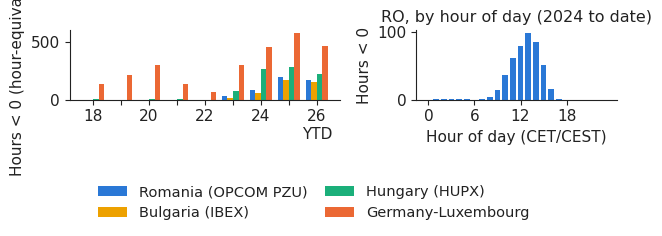

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.4), gridspec_kw={'width_ratios': [1.35, 1]})
yrs = list(range(2018, Y + 1))
for i, z in enumerate(ZONES):
    axs[0].bar(np.array(yrs) + (i - 1.5) * 0.2, [neg[z].loc[y] for y in yrs], width=0.2, color=PAL[z], label=ZONE_NAME[z])
axs[0].set_ylabel('Hours < 0 (hour-equivalents)')
axs[0].set_xticks(yrs)
axs[0].set_xticklabels([(str(y)[2:] if y % 2 == 0 else '') if y < Y else f'{str(y)[2:]}\nYTD' for y in yrs])
axs[1].bar(hneg.index, hneg.values, color=PAL['RO'], width=0.75)
axs[1].set_xlabel('Hour of day (CET/CEST)')
axs[1].set_ylabel('Hours < 0')
axs[1].set_title('RO, by hour of day (2024 to date)')
axs[1].set_xticks(range(0, 24, 6))
legend_bottom(fig, ncol=2)
fig.tight_layout(rect=(0, 0.3, 1, 1))
plt.savefig('negative_prices.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()